# 24场 REPAIR 审计

范围：2026-10-19 12:20–13:20、14:35–15:35（上海时间）。

完整PnL−10.153166 USDC，平均−0.42304858；按场末最终收益累计的最大回撤11.434。29轮实际补仓：TP7、SL22；首次TP15，其中8轮转SL。8场尾仓赢家由CLOB接口核实。

## 数据与方法

按交易ID+订单ID去重；全部成交最终CONFIRMED。逐市场精确核对数量、USDC六位成本与Merge释放成本。逐轮成本与session平均成本的归因差额单列。无成交市场保留在均值分母；没有将未知结算或零API结果当成0收益。

In [1]:
import json, hashlib
from pathlib import Path
from decimal import Decimal as D
OUT=Path('/home/ubuntu/poly-maker/docs/development/reviews/20261019_repair_24_markets_1220_1535')
s=json.loads((OUT/'summary.json').read_text())
for src in json.loads((OUT/'source_manifest.json').read_text()):
    for item in [src,*src['supporting_sources']]:
        assert hashlib.sha256(Path(item['source']).read_bytes()).hexdigest()==item['sha256']
assert len(s['markets'])==24
print('24 journal hashes and 48 supporting source hashes verified')

24 journal hashes and 48 supporting source hashes verified


In [2]:
from IPython.display import display,Markdown,Image
table='|市场|完整PnL|剩YES|剩NO|\n|---|---:|---:|---:|\n'
for m in s['markets']:
    table+='| '+' | '.join(str(m[k]) for k in ['market','full_pnl','residual_yes','residual_no'])+' |\n'
display(Markdown(table))

|市场|完整PnL|剩YES|剩NO|
|---|---:|---:|---:|
| 12:20 | 1.280834 | 4.323336 | 0.000000 |
| 12:25 | -1.200000 | 0.0 | 0.0 |
| 12:30 | -0.350000 | 0.0 | 5.0 |
| 12:35 | -0.900000 | 0.00 | 0.0 |
| 12:40 | 0.747200 | 0.000000 | 0.565714 |
| 12:45 | -1.100000 | 0.0 | 0.0 |
| 12:50 | 0.003200 | 0.0 | 0.01 |
| 12:55 | 0.100000 | 0.0 | 0.00 |
| 13:00 | 0.0 | 0.0 | 0.0 |
| 13:05 | -1.950000 | 0.0 | 0.0 |
| 13:10 | -1.200000 | 0.0 | 0.0 |
| 13:15 | -1.050000 | 0.0 | 0.0 |
| 14:35 | 0.0 | 0.0 | 0.0 |
| 14:40 | 0.0 | 0.0 | 0.0 |
| 14:45 | -0.800000 | 0.0 | 0.0 |
| 14:50 | -0.675900 | 2.136341 | 0.000000 |
| 14:55 | -0.650000 | 0.0 | 0.0 |
| 15:00 | 0.0 | 0.0 | 0.0 |
| 15:05 | -0.850000 | 0.0 | 0.00 |
| 15:10 | -0.750000 | 0.0 | 0.0 |
| 15:15 | 0.544100 | 0.000000 | 2.708305 |
| 15:20 | 0.398700 | 0.27 | 0.0 |
| 15:25 | -0.850000 | 0.0 | 0.0 |
| 15:30 | -0.901300 | 0.0 | 0.27 |


In [3]:
total=sum((D(m['merge_pnl']) for m in s['markets']),D(0))
value=peak=mdd=D(0)
for m in s['markets']:
    value+=D(m['merge_pnl'])
    peak=max(peak,value)
    mdd=max(mdd,peak-value)
assert total==D(s['stats']['merge_pnl'])
assert mdd==D(s['stats']['realized_merge_max_drawdown']['amount'])
ep=[e for m in s['markets'] for e in m['episodes'] if e['repair_fill_mode']]
assert len(ep)==29
from collections import Counter
assert Counter(e['repair_fill_mode'] for e in ep)=={'TP':7,'SL':22}
assert Counter(e['first_exit_mode'] for e in ep)=={'TP':15,'SL':14}
local_pairs=sum((D(e['paired_pnl']) for e in ep),D(0))
assert abs(local_pairs+D(s['stats']['session_pool_cost_adjustment'])-total)<D('1e-9')
print('Merge total:',total,'Mean:',total/24,'Max drawdown:',mdd)
full_total=sum((D(m['full_pnl']) for m in s['markets']),D(0))
value=peak=full_dd=D(0)
for m in s['markets']:
    value+=D(m['full_pnl'])
    peak=max(peak,value)
    full_dd=max(full_dd,peak-value)
assert full_total==D('-10.153166') and full_dd==D('11.434')
assert sum((D(e['full_pnl']) for m in s['markets'] for e in m['episodes']),D(0))==full_total
ev=s['stats']['settlement_evidence']
assert hashlib.sha256(Path(ev['source']).read_bytes()).hexdigest()==ev['sha256']
print('Full PnL:',full_total,'Full max drawdown:',full_dd)

Merge total: -9.147776649394689831249185384 Mean: -0.3811573603914454096353827243 Max drawdown: 9.23642531000
Full PnL: -10.153166 Full max drawdown: 11.434000


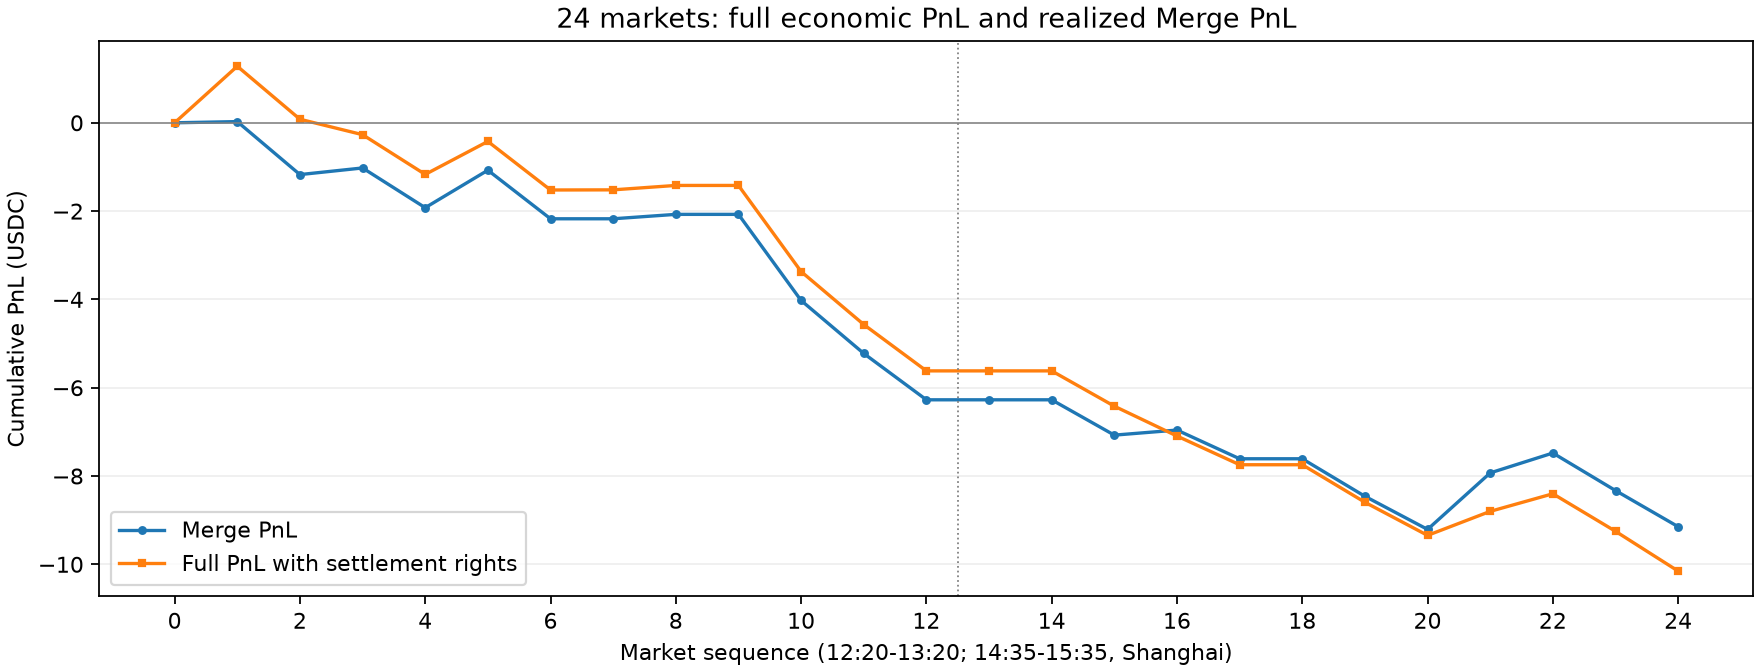

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(11,4.2),layout='constrained')
x=list(range(25)); y=[0]+[float(m['cumulative']) for m in s['markets']]
ax.plot(x,y,marker='o',markersize=3,label='Merge PnL')
ax.plot(x,[0]+[float(m['full_cumulative']) for m in s['markets']],marker='s',markersize=3,label='Full PnL with settlement rights')
ax.legend()
ax.axhline(0,color='gray',linewidth=.7); ax.axvline(12.5,color='gray',linestyle=':',linewidth=.8)
ax.set(xlabel='Market sequence (12:20-13:20; 14:35-15:35, Shanghai)',ylabel='Cumulative PnL (USDC)',title='24 markets: full economic PnL and realized Merge PnL')
ax.set_xticks(range(0,25,2));ax.grid(axis='y',alpha=.2)
fig.savefig(OUT/'cumulative-pnl.png',dpi=160);plt.close(fig)
display(Image(filename=str(OUT/'cumulative-pnl.png')))

## 解释与边界

TP初次出现15轮，实际TP成交7轮，另外8轮转SL。模式不是盈利标签。session成本池与逐轮配对归因差额+0.4124126506 USDC，对应残仓成本变化。8场尾仓赢家与token经CLOB核实，完整PnL−10.153166。累计场末PnL回撤不是盘中或现金账户回撤，也不代表redeem已到账。旧新12场不是随机对照，不作策略改动因果或长期EV判断。

运行异常细节见operations.json；逐场和逐轮时间线见README.md及timeline.json。